# Tydzień 2: Dane i EDA

Projekt: **Automatyczne streszczanie artykułów**. Zbiór danych: **CNN/DailyMail 3.0.0**.

Cel: poznać dane na tyle dobrze, żeby podjąć decyzje do preprocessingu i treningu.

## E1. Przygotowanie

In [1]:
from datasets import load_dataset
from transformers import AutoTokenizer
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nltk
import re

ds = load_dataset("abisee/cnn_dailymail", "3.0.0")
train = ds["train"].to_pandas()
test = ds["test"].to_pandas()
val = ds["validation"].to_pandas()

probka = train.sample(5000, random_state=42)

tokenizer = AutoTokenizer.from_pretrained("facebook/bart-base")
print(len(train), len(val), len(test), len(probka))

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


287113 13368 11490 5000


## E2. Rozkłady długości

In [2]:
train["art_slowa"] = train["article"].str.split().str.len()
train["hl_slowa"] = train["highlights"].str.split().str.len()
test["art_slowa"] = test["article"].str.split().str.len()
test["hl_slowa"] = test["highlights"].str.split().str.len()

pd.DataFrame({
    "train: artykuł": train["art_slowa"].describe(),
    "test: artykuł": test["art_slowa"].describe(),
    "train: streszczenie": train["hl_slowa"].describe(),
    "test: streszczenie": test["hl_slowa"].describe(),
}).round(0)


,train: artykuł,test: artykuł,train: streszczenie,test: streszczenie
count,287113.0,11490.0,287113.0,11490.0
mean,692.0,684.0,52.0,55.0
std,337.0,348.0,21.0,23.0
min,8.0,55.0,4.0,9.0
25%,443.0,419.0,38.0,40.0
50%,632.0,613.0,48.0,51.0
75%,877.0,876.0,60.0,64.0
max,2347.0,1954.0,1296.0,564.0


In [3]:
probka["art_tokeny"] = [len(x) for x in tokenizer(probka["article"].tolist())["input_ids"]]
probka["hl_tokeny"] = [len(x) for x in tokenizer(probka["highlights"].tolist())["input_ids"]]

probka[["art_tokeny", "hl_tokeny"]].describe().round(0)


,art_tokeny,hl_tokeny
count,5000.0,5000.0
mean,872.0,68.0
std,420.0,26.0
min,70.0,9.0
25%,557.0,51.0
50%,793.0,64.0
75%,1100.0,79.0
max,2543.0,464.0


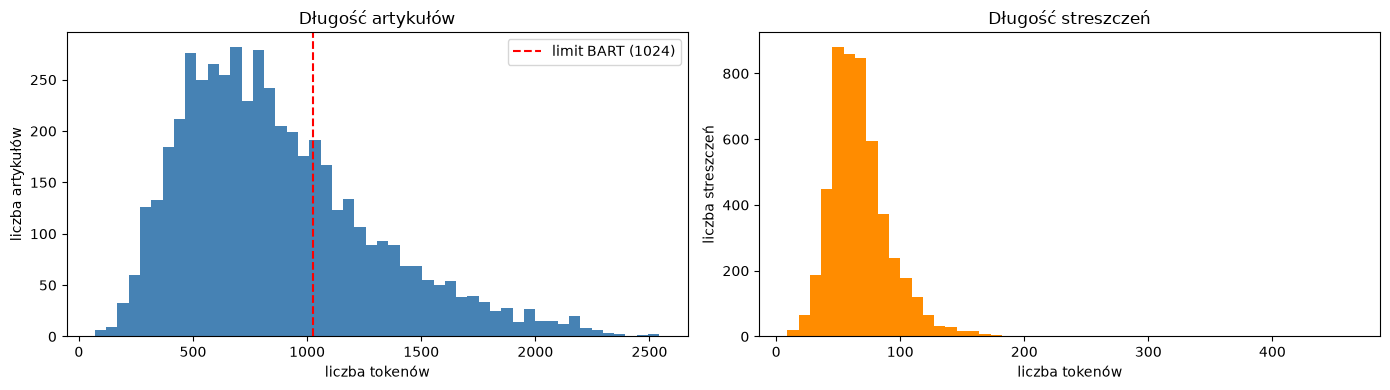

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(probka["art_tokeny"], bins=50, color="steelblue")
axes[0].axvline(1024, color="red", linestyle="--", label="limit BART (1024)")
axes[0].set_title("Długość artykułów")
axes[0].set_xlabel("liczba tokenów")
axes[0].set_ylabel("liczba artykułów")
axes[0].legend()

axes[1].hist(probka["hl_tokeny"], bins=50, color="darkorange")
axes[1].set_title("Długość streszczeń")
axes[1].set_xlabel("liczba tokenów")
axes[1].set_ylabel("liczba streszczeń")

plt.tight_layout()
plt.show()


### Wnioski z E2

- Rozkład długości artykułów i streszczeń jest **prawoskośny**: większość artykułów ma 500–800 tokenów, ale długi ogon sięga ~2500 tokenów.
- Średnia jest wyższa od mediany (artykuły: 872 vs 793 tokeny), bo kilka bardzo długich artykułów podnosi średnią. Dla takich rozkładów mediana lepiej opisuje typowy artykuł.
- Train i test mają podobne długości: średnio 692 vs 684 słowa w artykułach i 52 vs 55 słów w streszczeniach. Model będzie oceniany na danych podobnych do tych, na których się uczy.
- Jedno słowo to średnio ok. 1,26 tokenu (872 tokeny / 692 słowa), więc limit 1024 tokenów to ok. 800 słów.
- **Do sprawdzenia w E7:** artykuł z 8 słowami i streszczenie z 1296 słowami (dłuższe niż przeciętny artykuł).


## E3. Obcinanie i limity długości

In [8]:
dlugie = (probka["art_tokeny"] > 1024).mean()
print(f"Artykuły > 1024 tokenów: {dlugie:.1%}")

Artykuły > 1024 tokenów: 30.6%


In [9]:
np.percentile(probka["hl_tokeny"], [50, 90, 95, 99])

array([ 64.,  99., 114., 150.])

In [10]:
print(f"Streszczenia ≤ 128 tokenów: {(probka['hl_tokeny'] <= 128).mean():.1%}")

Streszczenia ≤ 128 tokenów: 97.6%


### Wnioski z E3

- Wiecej niż 1044 tokeny ma 30.6% artykułu. 
- Długości streszczeń w tokenach?, a 99 percentyl wynosi 114.
- Wybieram max_target_length = 128, bo mieści ok. 97% streszczeń (95. percentyl to ~114 tokenów), a dłuższe są rzadkie i często nietypowe. Większy limit zwiększyłby zużycie pamięci bez wyraźnej korzyści.

## E4. Kompresja

count    287113.000
mean          0.091
std           0.074
min           0.005
25%           0.055
50%           0.078
75%           0.113
max          19.000
Name: kompresja, dtype: float64

Streszczenie dłuższe niż połowa artykułu: 207
Streszczenie dłuższe niż cały artykuł: 26


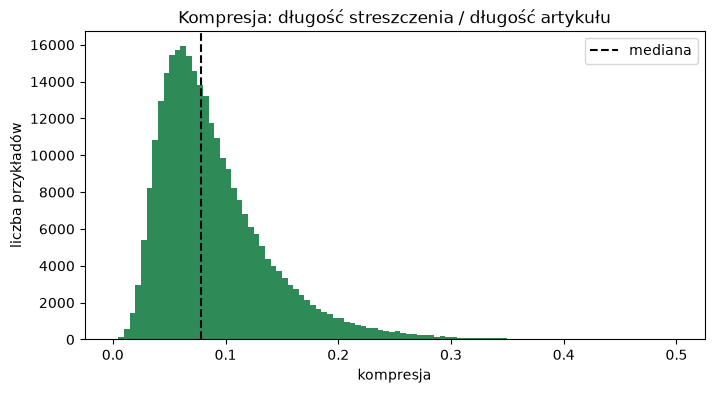

In [11]:
train["kompresja"] = train["hl_slowa"] / train["art_slowa"]

print(train["kompresja"].describe().round(3))
print(f"\nStreszczenie dłuższe niż połowa artykułu: {(train['kompresja'] > 0.5).sum()}")
print(f"Streszczenie dłuższe niż cały artykuł: {(train['kompresja'] > 1).sum()}")

plt.figure(figsize=(8, 4))
plt.hist(train["kompresja"], bins=100, range=(0, 0.5), color="seagreen")
plt.axvline(train["kompresja"].median(), color="black", linestyle="--", label="mediana")
plt.title("Kompresja: długość streszczenia / długość artykułu")
plt.xlabel("kompresja")
plt.ylabel("liczba przykładów")
plt.legend()
plt.show()

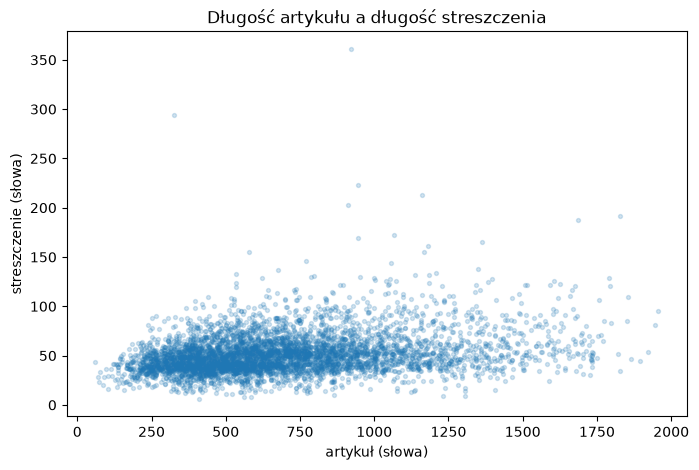

Korelacja Pearsona: 0.29


In [12]:
probka["art_slowa"] = probka["article"].str.split().str.len()
probka["hl_slowa"] = probka["highlights"].str.split().str.len()

plt.figure(figsize=(8, 5))
plt.scatter(probka["art_slowa"], probka["hl_slowa"], alpha=0.2, s=8)
plt.title("Długość artykułu a długość streszczenia")
plt.xlabel("artykuł (słowa)")
plt.ylabel("streszczenie (słowa)")
plt.show()

print(f"Korelacja Pearsona: {probka['art_slowa'].corr(probka['hl_slowa']):.2f}")


## Wnioski z E4

- Mediana kompresji wynosi 0,078: streszczenie ma ok. 1/13 długości artykułu. Średnia (0,091) jest wyższa od mediany, więc rozkład jest prawoskośny. W teście mediana to 0,086, czyli podobnie.
- Korelacja długości artykułu i streszczenia jest słaba (0,29). Dłuższe artykuły mają tylko trochę dłuższe streszczenia, bo redakcja pisała zwykle podobną liczbę punktów (ok. 4) niezależnie od długości tekstu.
- **Do sprawdzenia w E7:** 26 przykładów ma streszczenie dłuższe niż artykuł (maksymalnie 19 razy dłuższe). To błędy w danych.

## E5. Lead bias

In [13]:
def slowa(tekst):
    """Zbiór słów z tekstu: małe litery, bez interpunkcji."""
    return set(re.findall(r"[a-z0-9]+", tekst.lower()))

def pozycje_zrodlowe(artykul, streszczenie):
    """Dla każdego punktu streszczenia: względna pozycja najbardziej podobnego zdania w artykule."""
    zdania_art = nltk.sent_tokenize(artykul)
    slowa_art = [slowa(z) for z in zdania_art]
    wynik = []
    for zdanie in streszczenie.split("\n"):
        s = slowa(zdanie)
        if not s:
            continue
        pokrycie = [len(s & a) / len(s) for a in slowa_art]   # jaka część słów punktu jest w danym zdaniu
        wynik.append(np.argmax(pokrycie) / len(zdania_art))   # pozycja najlepszego zdania, od 0 do 1
    return wynik

pozycje = pd.Series([p for a, h in zip(probka["article"][:2000], probka["highlights"][:2000])
                     for p in pozycje_zrodlowe(a, h)])

print(f"Liczba przeanalizowanych punktów streszczeń: {len(pozycje)}")
print(f"Z pierwszych 10% artykułu: {(pozycje < 0.1).mean():.1%}")
print(f"Z pierwszych 30% artykułu: {(pozycje < 0.3).mean():.1%}")
print(f"Z drugiej połowy artykułu: {(pozycje >= 0.5).mean():.1%}")


Liczba przeanalizowanych punktów streszczeń: 7548
Z pierwszych 10% artykułu: 31.1%
Z pierwszych 30% artykułu: 63.7%
Z drugiej połowy artykułu: 20.4%


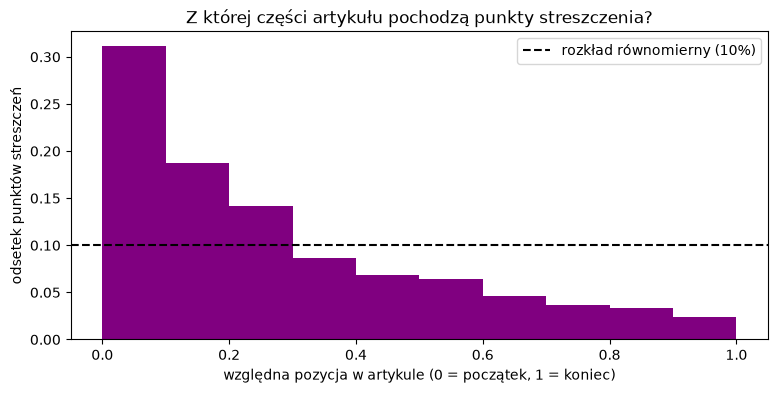

In [14]:
plt.figure(figsize=(9, 4))
plt.hist(pozycje, bins=10, range=(0, 1), weights=np.ones(len(pozycje)) / len(pozycje), color="purple")
plt.axhline(0.1, color="black", linestyle="--", label="rozkład równomierny (10%)")
plt.title("Z której części artykułu pochodzą punkty streszczenia?")
plt.xlabel("względna pozycja w artykule (0 = początek, 1 = koniec)")
plt.ylabel("odsetek punktów streszczeń")
plt.legend()
plt.show()

### Wnioski z E5

- Z pierwszych 10% artykułu pochodzi 31,1% punktów streszczeń, a z pierwszych 30% artykułu 63,7%. Z drugiej połowy pochodzi tylko 20.4%.
- Przy rozkładzie równomiernym byłoby to 10% i 30%. Pierwsza dziesiąta część artykułu jest więc źródłem streszczeń ok. 3 razy częściej, niż wynikałoby z przypadku. To wyraźny **lead bias**: redakcja brała informacje głównie z początku artykułu.
- Obcinanie do 1024 tokenów (~800 słów) dotyczy ok. 30% artykułów i usuwa tylko ich końcówkę, z której pochodzi niewiele punktów streszczeń. Strata informacji będzie więc niewielka. To też wyjaśnia, dlaczego Lead-3 jest tak mocnym baseline'em.
- Ograniczenia metody: liczymy tylko wspólne słowa, więc częste słowa (the, a, in) zawyżają pokrycie, a parafrazy nie są wykrywane. Przy remisie `np.argmax` wybiera wcześniejsze zdanie, co może lekko zawyżać lead bias. Wynik jest przybliżony.

## E6. Szum w danych

Tabela wzorców we wszystkich podziałach

In [15]:
wzorce = {
    "By . (na początku)": r"^By \. ",
    "PUBLISHED: .": r"PUBLISHED: \.",
    "UPDATED: .": r"UPDATED: \.",
    "Scroll down for video": r"Scroll down for video",
    "(CNN)": r"\(CNN\)",
}

podzialy = {"train": train, "validation": val, "test": test}

szum = pd.DataFrame({
    nazwa: {wzorzec: df["article"].str.contains(regex).mean() * 100 for wzorzec, regex in wzorce.items()}
    for nazwa, df in podzialy.items()
}).round(1)

szum.loc["WARNING (w streszczeniach)"] = [
    round(df["highlights"].str.contains("WARNING").mean() * 100, 2) for df in podzialy.values()
]
szum   # wartości w procentach


,train,validation,test
By . (na początku),34.20,0.00,0.00
PUBLISHED: .,20.30,0.00,0.00
UPDATED: .,20.90,0.00,0.00
Scroll down for video,15.50,24.60,26.20
(CNN),26.30,8.90,9.30
WARNING (w streszczeniach),0.14,0.46,0.46


In [16]:
for artykul in train[train["article"].str.contains(r"^By \. ")]["article"].head(3):
    print(artykul[:400])
    print("-" * 80)

By . Daily Mail Reporter . Last updated at 11:05 PM on 17th June 2011 . Pleaded: Colton Harris-Moore, aka the Barefoot Bandit, pleaded guilty to a string of sensational thefts . The young Washington state man who gained international notoriety during a two-year run from the law in stolen boats, cars and planes has pleaded guilty to seven charges in the 'Barefoot Bandit' case. Colton Harris-Moore, 
--------------------------------------------------------------------------------
By . Daily Mail Reporter . Last updated at 11:23 AM on 30th June 2011 . A clot-busting drug that can reduce the chance of dying from a second heart attack by 20 per cent has been given the all clear by an NHS watchdog. Clot inhibitor Clopidogrel had been considered the 'gold standard' for current treatment regimes. However research shows that new drug, Ticagrelor, cuts the overall risk of dying fr
--------------------------------------------------------------------------------
By . Daily Mail Reporter . Last upda

In [17]:
wzorzec = "Scroll down for video"
for artykul in train[train["article"].str.contains(wzorzec)]["article"].head(3):
    i = artykul.find(wzorzec)
    print("..." + artykul[max(0, i - 150): i + 150] + "...")
    print("-" * 80)

...ay, Florida. The brothers were only playing and thought the gun was broken and unloaded, but the pellet ended up getting lodged inside Tommy's brain. Scroll down for video . Recovering: Tommy Gallagher, 12, was almost fatally shot by his nine-year-old brother Jamey with a BB gun at their home in Tam...
--------------------------------------------------------------------------------
... hopes God punishes the man, who had been tipped as the next French president. 'We are poor, but we are good,' she said. 'I don't think about money.' Scroll down for video . Accused: Ms Diallo said that she wants former IMF boss Strauss-Kahn to be sent to jail . The hotel maid said that she did not ...
--------------------------------------------------------------------------------
...onate' their earliest recollections on the kids' movie franchise. When they reach one million memories, Disney will donate £1million for the charity. Scroll down for videos . Looking back: Sir Michael Caine talks about hi

### Wnioski z E6

- **Train różni się od validation i test.** Podpis autora i daty (`By .` 34%, `PUBLISHED: .` 20%, `UPDATED: .` 21%) występują tylko w train, a w validation i test nie ma ich wcale. Train ma też więcej artykułów CNN (26% vs ~9%). Validation i test są do siebie bardzo podobne.
- Prawdopodobna przyczyna: zbiór podzielono według daty publikacji (Hermann et al., 2015), a w międzyczasie zmienił się format strony Daily Mail. To przesunięcie rozkładu (distribution shift) między danymi treningowymi a testowymi.
- To problem dla modelu: w co trzecim artykule treningowym początek to śmieć, a lead bias (E5) uczy model, że początek jest najważniejszy. Śmieć zajmuje też miejsce w limicie 1024 tokenów.
- „Scroll down for video” występuje we wszystkich podziałach (16–26%) i nie niesie informacji o treści.
- Decyzja do preprocessingu: usunąć podpis autora i daty z początku artykułów oraz „Scroll down for video”. Ta sama funkcja czyszcząca będzie stosowana do artykułów w train, validation, test i w API. Streszczeń referencyjnych w teście nie zmieniam.

## E7. Duplikaty i bardzo krótkie artykuły

In [18]:
print(f"Zduplikowane artykuły: {train['article'].duplicated().sum()}")
print(f"Zduplikowane streszczenia: {train['highlights'].duplicated().sum()}")
print(f"Zduplikowane całe pary (artykuł + streszczenie): {train.duplicated(['article', 'highlights']).sum()}")

Zduplikowane artykuły: 3108
Zduplikowane streszczenia: 4916
Zduplikowane całe pary (artykuł + streszczenie): 3098


In [19]:
for prog in [20, 50, 100]:
    print(f"Artykuły krótsze niż {prog} słów: {(train['art_slowa'] < prog).sum()}")
print(f"Streszczenie dłuższe niż artykuł: {(train['hl_slowa'] > train['art_slowa']).sum()}")

print("\n=== NAJKRÓTSZE ARTYKUŁY ===")
for i in train["art_slowa"].nsmallest(4).index:
    print(f"[{train.loc[i, 'art_slowa']} słów] ARTYKUŁ: {train.loc[i, 'article'][:150]}")
    print(f"   STRESZCZENIE: {train.loc[i, 'highlights'][:150]}\n")

print("=== NAJWIĘKSZA KOMPRESJA (streszczenie >> artykuł) ===")
for i in train["kompresja"].nlargest(3).index:
    print(f"[kompresja {train.loc[i, 'kompresja']:.1f}] ARTYKUŁ: {train.loc[i, 'article'][:150]}")
    print(f"   STRESZCZENIE: {train.loc[i, 'highlights'][:150]}\n")

Artykuły krótsze niż 20 słów: 3
Artykuły krótsze niż 50 słów: 29
Artykuły krótsze niż 100 słów: 432
Streszczenie dłuższe niż artykuł: 26

=== NAJKRÓTSZE ARTYKUŁY ===
[8 słów] ARTYKUŁ: Downton Abbey's famously grim butler, Mr Bates .
   STRESZCZENIE: And now for the good news . . . Following a particularly grim week, here’s a compendium of some of the world’s most comforting headlines: .
Supermodel

[18 słów] ARTYKUŁ: Congressman Jared Polis . (D) Colorado: District 02 . Congressman Jason Chaffetz . (R) Utah: District 03 .
   STRESZCZENIE: Two freshman representatives document their experience for CNN .
Rep. Jared Polis is a Democrat representing Colorado's Second district .
Rep. Jason C

[18 słów] ARTYKUŁ: Congressman Jared Polis . (D) Colorado: District 02 . Congressman Jason Chaffetz . (R) Utah: District 03 .
   STRESZCZENIE: Video: Hand-held cams track freshmen moves .
Two freshman representatives document their experience for CNN .
Rep. Jared Polis is a Democrat represent

[21 słów

### Wnioski z E7

- W train jest 3108 zduplikowanych artykułów, z czego 3098 to całe pary (artykuł + streszczenie) wpisane kilka razy. Decyzja: usunąć powtórzenia, zostawiając pierwsze wystąpienie. Model widziałby te same przykłady wielokrotnie, co sprzyja przeuczeniu.
- Ok. 1800 różnych artykułów ma identyczne streszczenie (4916 zduplikowanych streszczeń minus 3098 powtórzonych par), tak jak w teście w tygodniu 1. To artykuły o tym samym wydarzeniu. Decyzja: zostawić, bo streszczenie pasuje do treści.
- Najkrótsze „artykuły” to nie artykuły: podpis pod zdjęciem (8 słów), lista nazwisk, dane techniczne samochodu. Właściwa treść trafiła do streszczenia. W 26 przypadkach streszczenie jest dłuższe niż artykuł (maksymalnie 19 razy). Model uczyłby się na nich wymyślać treść, której nie ma w tekście, czyli halucynować.
- Decyzja: usunąć artykuły krótsze niż 50 słów (29 przykładów) i pary ze streszczeniem dłuższym niż artykuł (26 przykładów). Próg 50 słów jest poniżej najkrótszego artykułu w teście (55 słów).
- Łącznie usuwam ok. 3150 przykładów, czyli ok. 1,1% zbioru treningowego. Strata danych jest pomijalna.
- Zbioru testowego nie zmieniam (decyzja z tygodnia 1).

## E8. Przeciek danych

In [20]:
art_train = set(train["article"])
art_val = set(val["article"])
art_test = set(test["article"])

print(f"train ∩ test:       {len(art_train & art_test)}")
print(f"train ∩ validation: {len(art_train & art_val)}")
print(f"validation ∩ test:  {len(art_val & art_test)}")

train ∩ test:       0
train ∩ validation: 1
validation ∩ test:  0


In [21]:
wspolne = art_train & art_val
for a in wspolne:
    print(a[:300])

The Irishman left fighting for life by his brother in an alleged one-punch attack has called for the charges against his sibling to be dropped. Patrick Lyttle today accompanied his elder brother Barry to court for the first time, wearing a dark beanie. 'This should not be going ahead, it's not a mat


### Wnioski z E8

- Przeciek danych między train a test nie występuje: 0 wspólnych artykułów. Wynik na zbiorze testowym będzie więc uczciwą oceną modelu na tekstach, których nie widział podczas treningu.
- Między train a validation jest 1 wspólny artykuł na 13 368 przykładów walidacyjnych (0,007%). Wpływ na strojenie parametrów generowania w tygodniu 4 jest pomijalny. Dla porządku usunę ten artykuł z train w preprocessingu, żeby walidacja była w pełni czysta.
- Między validation a test nie ma wspólnych artykułów.
- Ograniczenie: porównywane są tylko identyczne teksty. Artykuły różniące się drobnymi szczegółami (np. jednym zdaniem) nie zostałyby wykryte.

## E9. Wnioski i decyzje

| Decyzja | Wartość | Uzasadnienie (z którego zadania) |
|---|---|---|
| max_input_length | ... | E3 |
| max_target_length | ... | E3 |
| Wzorce do usunięcia z artykułów | ... | E6 |
| Wzorce do usunięcia ze streszczeń | ... | E6, tydzień 1 |
| Duplikaty w train | usunąć / zostawić | E7 |
| Bardzo krótkie artykuły | usunąć poniżej ... słów | E7 |
| Zbiór testowy | bez zmian | tydzień 1: porównywalność z literaturą |
| Wielkość podzbioru treningowego | ... | ograniczenia sprzętu z tygodnia 1 |

### Podsumowanie EDA

- Rozkłady długości są prawoskośne, a train i test mają podobne długości (E2).
- Streszczenia mają typowo ~64 tokeny i ok. 1/13 długości artykułu, niezależnie od jego długości (E3, E4).
- Wyraźny lead bias: 31% punktów streszczeń pochodzi z pierwszych 10% artykułu (E5). Obcinanie do 1024 tokenów kosztuje więc niewiele.
- Najważniejsze odkrycie: train różni się od validation i test formatem artykułów Daily Mail (distribution shift, E6), więc czyszczenie train jest kluczowe.
- Łącznie z train zostanie usunięte ok. 1,1% przykładów (E7, E8). Przecieku do testu nie ma.